In [1]:
import os
import cv2
import argparse
from ultralytics  import YOLO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from analyze_errors.matching import match_gt_with_results
from analyze_errors.metrics_calculate import compute_map, box_metrics_calculate
from analyze_errors.visualization import visualize_prediction
from analyze_errors.eigen_cam import EigenCAM, visualize_prediction_with_cam

# === parameters ===
RANDOM_STATE = 42

In [2]:
path2data_file = "./data.yaml"
split = "val"
path2model = "./runs/detect/baseline_v0/aug_none_only_detect/weights/best.pt"
imgsize = 512
project = "baseline_v0"
exp_name = "errors_analyze"
conf = 0.001

nms_iou = 0.6
match_iou = 0.5

batch_size = 32

In [4]:
# === model init ===
model = YOLO(path2model)

In [5]:
results = model.predict(
    source="./dataset_yolo/val_fold_1.txt",
    imgsz=imgsize,
    batch=batch_size,
    workers=2,
    seed=RANDOM_STATE,
    deterministic=True,
    conf=conf, # 0.0001 # низкий порог для честного расчёта mAP
    iou=nms_iou, # IoU для NMS при валидации
    verbose=False # Отключить печать
)

In [6]:
eigencam = EigenCAM(model, target_layer_idx=-2)   # P5; для мелких объектов попробуй 15 (P3)

### mAP calculate

In [5]:
m = compute_map(results, "./dataset_yolo/labels", num_classes=1)
print(f"mAP0.5: {m['map_05']:0.4f}")
print(f"mAP0.5-0.95: {m['map_50_95']:.4f}")
print(m)

mAP0.5: 0.0910
mAP0.5-0.95: 0.0317
{'ap_table': array([[   0.091015,    0.079135,    0.057031,    0.039079,     0.02245,    0.014609,   0.0078272,   0.0057599,  0.00019111,  5.2394e-05]]), 'map_05': 0.09101500512570601, 'map_50_95': 0.031714973095370545, 'per_iou_map': {0.5: 0.09101500512570601, 0.55: 0.07913528484196095, 0.6000000000000001: 0.05703056050185333, 0.6500000000000001: 0.039079488042682534, 0.7000000000000002: 0.02244990427576147, 0.7500000000000002: 0.014608850284219765, 0.8000000000000003: 0.007827234813339776, 0.8500000000000003: 0.005759894329453899, 0.9000000000000004: 0.00019111479728364838, 0.9500000000000004: 5.2393941444073366e-05}, 'per_class_ap_05': {0: 0.09101500512570601}}


### TP, FP, FN, Precision, Recall for GT

In [18]:
boxes_metrics = []
for c in np.linspace(0.05, 0.9, 18):
    m = box_metrics_calculate(results, "./dataset_yolo/labels", iou=match_iou, conf=c)
    boxes_metrics.append({
        "conf": c,
        "iou": match_iou,
        "metrics": m 
    })

In [21]:
for item in boxes_metrics:
    ii = item['metrics']
    print(f"conf: {item['conf']:.2f}, | TP: {ii['TP']} | FP: {ii['FP']} | FN: {ii['FN']} | P: {ii['P']:.4f} R: {ii['R']:.4f} | F1: {ii['F1']:.4f}")

conf: 0.05, | TP: 203 | FP: 678 | FN: 986 | P: 0.2304 R: 0.1707 | F1: 0.1961
conf: 0.10, | TP: 125 | FP: 248 | FN: 1064 | P: 0.3351 R: 0.1051 | F1: 0.1601
conf: 0.15, | TP: 77 | FP: 102 | FN: 1112 | P: 0.4302 R: 0.0648 | F1: 0.1126
conf: 0.20, | TP: 49 | FP: 52 | FN: 1140 | P: 0.4851 R: 0.0412 | F1: 0.0760
conf: 0.25, | TP: 37 | FP: 27 | FN: 1152 | P: 0.5781 R: 0.0311 | F1: 0.0591
conf: 0.30, | TP: 22 | FP: 10 | FN: 1167 | P: 0.6875 R: 0.0185 | F1: 0.0360
conf: 0.35, | TP: 16 | FP: 5 | FN: 1173 | P: 0.7619 R: 0.0135 | F1: 0.0264
conf: 0.40, | TP: 11 | FP: 3 | FN: 1178 | P: 0.7857 R: 0.0093 | F1: 0.0183
conf: 0.45, | TP: 6 | FP: 2 | FN: 1183 | P: 0.7500 R: 0.0050 | F1: 0.0100
conf: 0.50, | TP: 2 | FP: 0 | FN: 1187 | P: 1.0000 R: 0.0017 | F1: 0.0034
conf: 0.55, | TP: 0 | FP: 0 | FN: 1189 | P: 0.0000 R: 0.0000 | F1: 0.0000
conf: 0.60, | TP: 0 | FP: 0 | FN: 1189 | P: 0.0000 R: 0.0000 | F1: 0.0000
conf: 0.65, | TP: 0 | FP: 0 | FN: 1189 | P: 0.0000 R: 0.0000 | F1: 0.0000
conf: 0.70, | TP: 0 

### Visualization

In [13]:
result_item = results[0]
stem = result_item.path.split("\\")[-1].split('.')[0]
path2label = f"./dataset_yolo/labels/{stem}.txt"

matches, un_gt, un_pred, gt = match_gt_with_results(
    result_item, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

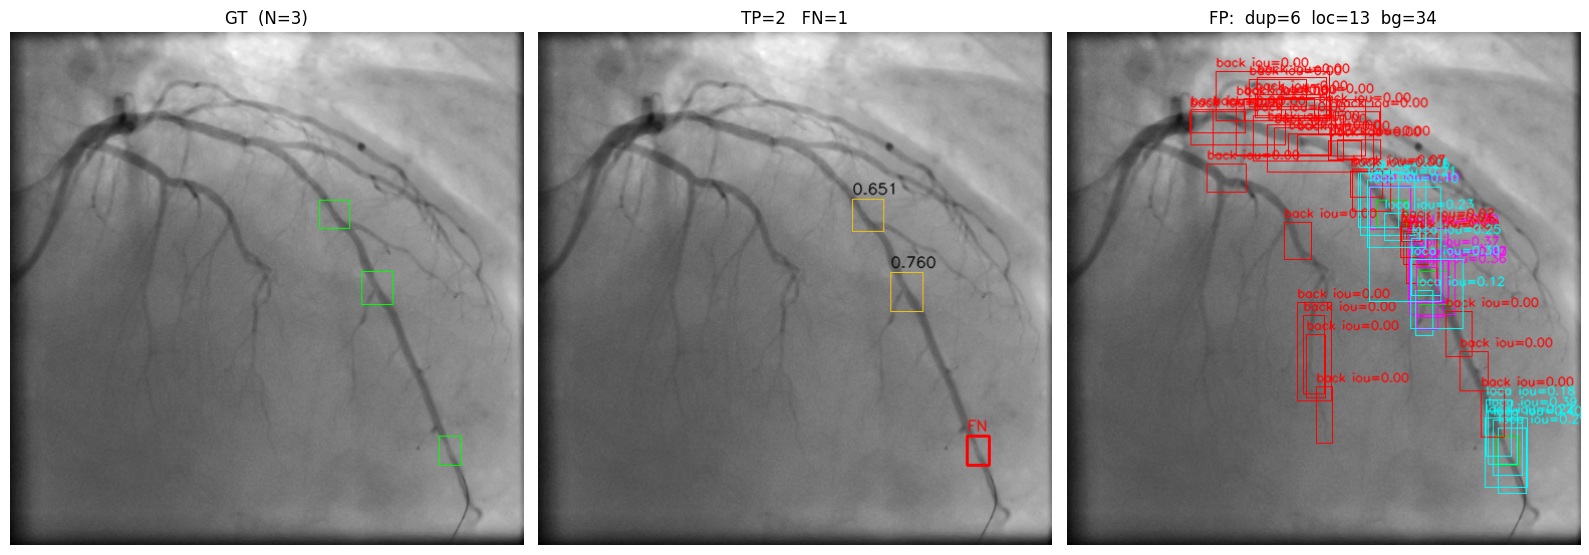

In [14]:
visualize_prediction(
    result_item, matches, un_gt, un_pred, gt
)

### EigenCAM visualization

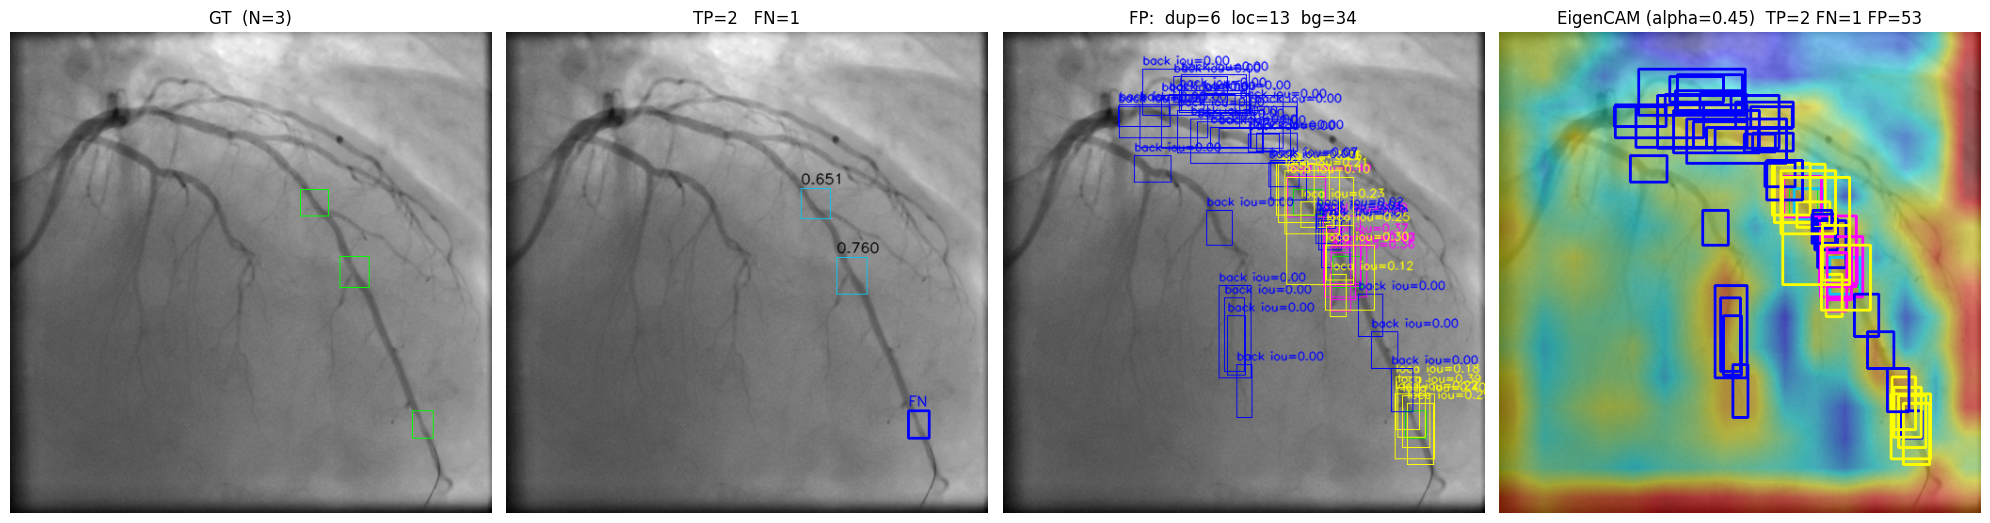

In [16]:
result_cam, heatmap, feat_shape = eigencam(result_item.path, imgsz=imgsize)

matches, un_gt, un_pred, gt = match_gt_with_results(
    result_cam, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

visualize_prediction_with_cam(result_cam, matches, un_gt, un_pred, gt, heatmap, alpha=0.45, figsize=(20, 15))
eigencam.remove_hooks()